# جلسهٔ ۳ — درخت چطور سؤالش را انتخاب می‌کند

*خلوص، غافلگیری، و بهره — قهرمانِ سؤال‌ها.*

In [1]:
# COURSE SETUP — identical in every session. Just run it. (5 seconds)
%matplotlib inline
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree
from scipy.stats import entropy as _sc_entropy

def surprise(labels):
    # the surprise level of a box (entropy) — from COUNTS, no formula needed.
    # base=2: measured in "bits" — the same numbers we used on the board.
    _, counts = np.unique(labels, return_counts=True)
    return float(_sc_entropy(counts, base=2))

plt.rcParams["figure.figsize"] = (8, 4)
print("Setup OK — let's measure some questions.")


Setup OK — let's measure some questions.


# PART 0 — نمایش: ماشین چطور سؤالش را انتخاب می‌کند

جلسهٔ قبل ماشین `وزن ≥ ۱۴` را پرسید و قول دادیم بگوییم **چرا**.
حالا بازیِ کلاس را جلوی چشم‌تان اجرا می‌کنیم: ماشین همهٔ سؤال‌های ممکن را
امتحان می‌کند، به هر کدام یک نمره می‌دهد — و قهرمان را انتخاب می‌کند.


In [ ]:
# DEMO: the machine tests questions and scores them
animals = pd.DataFrame({
    "weight": [4.5, 3.0, 6.0, 5.0,   22, 32, 28, 38,   4, 3.5, 4.5],
    "ear_length": [5, 7, 4, 6,        9, 12, 11, 13,    11, 9.5, 10],
    "group": ["cat", "cat", "cat", "cat",
              "big dog", "big dog", "big dog", "big dog",
              "small dog", "small dog", "small dog"],
}, index=["persian", "siamese", "garfield", "chartreux",
          "bulldog", "german", "golden", "doberman",
          "poodle", "yorkshire", "papillon"])
X = animals[["weight", "ear_length"]]
y = animals["group"]


def surprise_after(feature, th):
    # a question's score: average surprise of the two sides of the door, after splitting
    left  = y[animals[feature] <  th]
    right = y[animals[feature] >= th]
    if len(left) == 0 or len(right) == 0:
        return None
    return (len(left) * surprise(left) + len(right) * surprise(right)) / len(y)

before = surprise(y)
print(f"surprise of the main box (11 animals): {before:.2f}")
print()
print("scoreboard - question | surprise after | question score (gain):")
candidates = [("weight", 14), ("ear_length", 8.25), ("weight", 3.25), ("ear_length", 4.5), ("weight", 30)]
for feature, th in candidates:
    after = surprise_after(feature, th)
    print(f"  {feature} >= {th:5}  |  {after:.2f}  |  gain = {before - after:.2f}")

print()
best = max(candidates, key=lambda c: before - surprise_after(*c))
print(f"the machine's champion: {best[0]} >= {best[1]}  (biggest gain)")
print("the very question we saw in session 2 — now we know where it came from.")


# PART A — جلسهٔ تدریس

*(این بخش را با معلم، در کلاس پر می‌کنیم.)*

## A1 — مرتب‌شدگی: کدام سؤال بهتر مرتب می‌کند؟

سؤالِ خوب، هر طرفِ در را «یک‌رنگ» می‌گذارد.
سؤالِ بیهوده، جعبه را تکه می‌کند ولی شلوغ‌ترش می‌کند.


In [3]:
# A1 — see two questions side by side: one sorts, one merely slices
animals = pd.DataFrame({
    "weight": [4.5, 3.0, 6.0, 5.0,   22, 32, 28, 38,   4, 3.5, 4.5],
    "ear_length": [5, 7, 4, 6,        9, 12, 11, 13,    11, 9.5, 10],
    "group": ["cat", "cat", "cat", "cat",
              "big dog", "big dog", "big dog", "big dog",
              "small dog", "small dog", "small dog"],
}, index=["persian", "siamese", "garfield", "chartreux",
          "bulldog", "german", "golden", "doberman",
          "poodle", "yorkshire", "papillon"])
X = animals[["weight", "ear_length"]]
y = animals["group"]

for feature, th, verdict in [("weight", 14, "good question"),
                             ("ear_length", 4.5, "useless question")]:
    left  = y[animals[feature] <  th].value_counts()
    right = y[animals[feature] >= th].value_counts()
    print(f"--- {feature} >= {th}  ({verdict}) ---")
    print("  no door :", dict(left))
    print("  yes door:", dict(right))
    print()

# good question: one side is only big dogs (sorted). Useless question: both sides stay as mixed as before.


--- weight >= 14  (good question) ---
  no door : {'cat': np.int64(4), 'small dog': np.int64(3)}
  yes door: {'big dog': np.int64(4)}

--- ear_length >= 4.5  (useless question) ---
  no door : {'cat': np.int64(1)}
  yes door: {'big dog': np.int64(4), 'cat': np.int64(3), 'small dog': np.int64(3)}



## A2 — غافلگیری: شلوغیِ جعبه را عددی کنیم

سه تا کیسهٔ توپ داریم. از هر کدام نمی‌بینیم یک توپ بیرون می‌کشیم:
- کیسهٔ ۱: ۸ توپ آبی
- کیسهٔ ۲: ۴ آبی + ۴ قرمز
- کیسهٔ ۳: ۳ آبی + ۳ قرمز + ۲ سبز

قبل از کشیدن، چقدر مطمئنید؟ همان «چقدر مطمئن نیستم»، **غافلگیری (آنتروپی)** است.


In [4]:
# A2 — the machine's ruler: the surprise of each bag
bags = {
    "bag 1 (8 blue)":            ["blue"] * 8,
    "bag 2 (4 blue + 4 red)":    ["blue"] * 4 + ["red"] * 4,
    "bag 3 (3 blue + 3 red + 2 green)": ["blue"] * 3 + ["red"] * 3 + ["green"] * 2,
}
for name, bag in bags.items():
    print(f"{name:35} -> surprise: {surprise(bag):.2f}")

# a pure box = 0 surprise. The more mixed, the bigger the number. That's it!


bag 1 (8 blue)                      -> surprise: 0.00
bag 2 (4 blue + 4 red)              -> surprise: 1.00
bag 3 (3 blue + 3 red + 2 green)    -> surprise: 1.56


In [5]:
# A2b — how surprising is the 11-animal box? (guess first, then run)
animals = pd.DataFrame({
    "weight": [4.5, 3.0, 6.0, 5.0,   22, 32, 28, 38,   4, 3.5, 4.5],
    "ear_length": [5, 7, 4, 6,        9, 12, 11, 13,    11, 9.5, 10],
    "group": ["cat", "cat", "cat", "cat",
              "big dog", "big dog", "big dog", "big dog",
              "small dog", "small dog", "small dog"],
}, index=["persian", "siamese", "garfield", "chartreux",
          "bulldog", "german", "golden", "doberman",
          "poodle", "yorkshire", "papillon"])
X = animals[["weight", "ear_length"]]
y = animals["group"]

print("box composition:", dict(y.value_counts()))
print(f"surprise of the animal box: {surprise(y):.2f}")


box composition: {'cat': np.int64(4), 'big dog': np.int64(4), 'small dog': np.int64(3)}
surprise of the animal box: 1.57


## A3 — بازیِ رتبه‌بندی سؤال‌ها

نمرهٔ هر سؤال = غافلگیریِ قبل − غافلگیریِ بعد.
سؤالی که بیشترین غافلگیری را بردارد، **قهرمان** است — ماشین همیشه قهرمان را انتخاب می‌کند.


In [6]:
# A3 — the scoreboard: the machine measures every question
animals = pd.DataFrame({
    "weight": [4.5, 3.0, 6.0, 5.0,   22, 32, 28, 38,   4, 3.5, 4.5],
    "ear_length": [5, 7, 4, 6,        9, 12, 11, 13,    11, 9.5, 10],
    "group": ["cat", "cat", "cat", "cat",
              "big dog", "big dog", "big dog", "big dog",
              "small dog", "small dog", "small dog"],
}, index=["persian", "siamese", "garfield", "chartreux",
          "bulldog", "german", "golden", "doberman",
          "poodle", "yorkshire", "papillon"])
X = animals[["weight", "ear_length"]]
y = animals["group"]

def gain_of(feature, th):
    left  = y[animals[feature] <  th]
    right = y[animals[feature] >= th]
    if len(left) == 0 or len(right) == 0:
        return 0.0
    after = (len(left) * surprise(left) + len(right) * surprise(right)) / len(y)
    return surprise(y) - after

rows = []
for feature in ("weight", "ear_length"):
    for th in (3.25, 4.5, 8.25, 14, 30):
        rows.append((f"{feature} >= {th}", gain_of(feature, th)))
board = pd.DataFrame(rows, columns=["question", "gain"]).sort_values("gain", ascending=False)
board.index = range(1, len(board) + 1)
print(f"surprise before each question: {surprise(y):.2f}")
print(board.to_string())

# two champions are tied (weight >= 14 and ear >= 8.25) — the machine keeps the first one it saw: weight.


surprise before each question: 1.57
              question      gain
1         weight >= 14  0.945660
2       weight >= 8.25  0.945660
3   ear_length >= 8.25  0.945660
4         weight >= 30  0.320402
5        weight >= 4.5  0.299896
6       weight >= 3.25  0.144487
7    ear_length >= 4.5  0.144487
8   ear_length >= 3.25  0.000000
9     ear_length >= 14  0.000000
10    ear_length >= 30  0.000000


In [7]:
# A3b — now only the light box (7 animals: 4 cats + 3 small dogs). Who is the champion?
light = animals[animals["weight"] < 14]
y_light = light["group"]
def gain_light(feature, th):
    left  = y_light[light[feature] <  th]
    right = y_light[light[feature] >= th]
    if len(left) == 0 or len(right) == 0:
        return 0.0
    after = (len(left) * surprise(left) + len(right) * surprise(right)) / len(y_light)
    return surprise(y_light) - after

print("light box composition:", dict(y_light.value_counts()))
print(f"surprise: {surprise(y_light):.2f}")
for feature, th in [("ear_length", 8.25), ("ear_length", 7.0), ("weight", 3.75)]:
    print(f"  {feature} >= {th:5} -> gain: {gain_light(feature, th):.2f}")

# champion: ear_length >= 8.25 — it makes the box fully pure (gain = 0.99 = all the surprise).
# this is the tree's second question from session 2: you found it yourselves.


light box composition: {'cat': np.int64(4), 'small dog': np.int64(3)}
surprise: 0.99
  ear_length >=  8.25 -> gain: 0.99
  ear_length >=   7.0 -> gain: 0.52
  weight >=  3.75 -> gain: 0.01


## A4 — لحظهٔ بزرگ: ماشین این بازی را روی تایتانیک بازی می‌کند

۷۱۲ مسافر (بعد از حذف سن‌های گم‌شده)، ۲۸۸ نفر زنده ماندند.
جعبهٔ تایتانیک چقدر غافلگیرکننده است؟


In [8]:
# A4 — the Titanic box
titanic = pd.read_csv(
    "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
).rename(columns=str.lower)
titanic = titanic[["survived", "pclass", "sex", "age", "fare", "embarked"]].dropna()
X_t = titanic[["pclass", "age", "fare"]].copy()
X_t["is_female"] = (titanic["sex"] == "female").astype(int)
y_t = titanic["survived"]

print(f"passengers: {len(y_t)} — survived: {y_t.sum()} ({y_t.mean():.0%})")
print(f"surprise of the Titanic box: {surprise(y_t):.2f}")


passengers: 712 — survived: 288 (40%)
surprise of the Titanic box: 0.97


## A5 — جدول امتیازها روی تایتانیک: قهرمان کیست؟

جلسهٔ ۱ روی «کدام ویژگی مهم‌تر است» رأی گرفتید.
امروز رأی‌تان عدد دارد.


In [9]:
# A5 — each feature's gain on Titanic (the best question of each feature)
titanic = pd.read_csv(
    "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
).rename(columns=str.lower)
titanic = titanic[["survived", "pclass", "sex", "age", "fare", "embarked"]].dropna()
X_t = titanic[["pclass", "age", "fare"]].copy()
X_t["is_female"] = (titanic["sex"] == "female").astype(int)
y_t = titanic["survived"]

def gain_feature(col):
    vals = sorted(X_t[col].unique())
    root = surprise(y_t)
    best = 0.0
    for i in range(len(vals) - 1):
        th = (vals[i] + vals[i + 1]) / 2
        left  = y_t[X_t[col] <= th]
        right = y_t[X_t[col] >  th]
        if len(left) == 0 or len(right) == 0:
            continue
        after = (len(left) * surprise(left) + len(right) * surprise(right)) / len(y_t)
        best = max(best, root - after)
    return best

board = pd.DataFrame(
    [(c, gain_feature(c)) for c in X_t.columns],
    columns=["feature", "gain"]).sort_values("gain", ascending=False)
board.index = range(1, len(board) + 1)
print(f"box surprise: {surprise(y_t):.2f}")
print(board.to_string())

# champion: is_female — the one the class voted for in session 1. The machine just said its number.
# (the men's box: 21% survived. the women's box: 75%.)


box surprise: 0.97
     feature      gain
1  is_female  0.214108
2     pclass  0.083014
3       fare  0.069298
4        age  0.018469


## A6 — کلِ راز، در چند خط

ماشین فکر نمی‌کند؛ می‌سنجد و بزرگ‌ترین را برمی‌دارد — برای هر گره، میلیون‌ها بار.


In [10]:
# A6 — the machine's game, in plain Python (on the animal box)
animals = pd.DataFrame({
    "weight": [4.5, 3.0, 6.0, 5.0,   22, 32, 28, 38,   4, 3.5, 4.5],
    "ear_length": [5, 7, 4, 6,        9, 12, 11, 13,    11, 9.5, 10],
    "group": ["cat", "cat", "cat", "cat",
              "big dog", "big dog", "big dog", "big dog",
              "small dog", "small dog", "small dog"],
}, index=["persian", "siamese", "garfield", "chartreux",
          "bulldog", "german", "golden", "doberman",
          "poodle", "yorkshire", "papillon"])
X = animals[["weight", "ear_length"]]
y = animals["group"]

def best_question(table, labels):
    best_gain, best_q = 0.0, None
    for feature in ("weight", "ear_length"):
        vals = sorted(table[feature].unique())
        for i in range(len(vals) - 1):
            th = (vals[i] + vals[i + 1]) / 2
            left  = labels[table[feature] <  th]
            right = labels[table[feature] >= th]
            if len(left) == 0 or len(right) == 0:
                continue
            after = (len(left) * surprise(left) + len(right) * surprise(right)) / len(labels)
            g = surprise(labels) - after
            if g > best_gain:
                best_gain, best_q = g, (feature, th)
    return best_q, best_gain

q, g = best_question(animals, y)
print(f"champion: {q[0]} >= {q[1]}  with gain {g:.2f}")

# and for node two, the same game on the light box:
light = animals[animals["weight"] < 14]
q2, g2 = best_question(light, light["group"])
print(f"light-box champion: {q2[0]} >= {q2[1]}  with gain {g2:.2f}")

# these two questions are exactly session 2's depth-2 tree. There is no line four.


champion: weight >= 14.0  with gain 0.95
light-box champion: ear_length >= 8.25  with gain 0.99


---

# PART B — تمرین‌های خانه (قبل از جلسهٔ حل مسئله)

## تمرین B1 — غافلگیریِ کیسه‌ها (۱ نمره)

سه کیسهٔ توپ داریم. غافلگیری (آنتروپی) هر کدام را با تابع `surprise` حساب کن
و جواب‌ها را در متغیرها بگذار (گرد نکن — همان عددی که چاپ می‌شود):

- کیسهٔ الف: ۱۰ توپ همه قرمز
- کیسهٔ ب: ۵ قرمز + ۵ آبی
- کیسهٔ ج: ۱ قرمز + ۹ آبی


In [11]:
# B1 — compute the bags' surprise
bag_a = ["red"] * 10
bag_b = ["red"] * 5 + ["blue"] * 5
bag_c = ["red"] * 1 + ["blue"] * 9

# TODO: use the surprise function (setup cell) to compute all three and store them in the variables
B1_surprise_a = None   # <-- your answer
B1_surprise_b = None   # <-- your answer
B1_surprise_c = None   # <-- your answer
print(f"A: {B1_surprise_a}, B: {B1_surprise_b}, C: {B1_surprise_c}")


A: None, B: None, C: None


## تمرین B2 — سؤالِ قهرمانِ جعبهٔ سبک (۱ نمره)

جعبهٔ سبک (۷ حیوان: ۴ گربه + ۳ سگ کوچک) را داری.
بین این سه سؤال، قهرمان کدام است؟ با تابع بهره حساب کن:

- `طول_گوش ≥ 8.25`
- `طول_گوش ≥ 7.0`
- `وزن ≥ 3.75`


In [12]:
# B2 — compute the gain of all three questions, pick the champion
light = animals[animals["weight"] < 14]
y_light = light["group"]

def gain_light(feature, th):
    left  = y_light[light[feature] <  th]
    right = y_light[light[feature] >= th]
    if len(left) == 0 or len(right) == 0:
        return 0.0
    after = (len(left) * surprise(left) + len(right) * surprise(right)) / len(y_light)
    return surprise(y_light) - after

# TODO: compute the three gains; put the champion question (full string, like "ear_length >= 8.25") in B2_champion
B2_gain_ears_825 = None   # <-- gain of question one
B2_gain_ears_70  = None   # <-- gain of question two
B2_gain_weight_375 = None # <-- gain of question three
B2_champion = ""          # <-- champion question name (string)
print(f"champion: {B2_champion}")


champion: 


## تمرین B3 — سؤالِ قهرمانِ تایتانیک (۱ نمره — تحویلِ امشب)

جدول امتیازهای تایتانیک را مثل سلول A5 بساز. قهرمان کدام ویژگی است؟
بهرهٔ او را هم بنویس. بعد جعبهٔ قهرمان را بکش: دو جعبه (بله/خیر) با تعداد زنده‌مانده‌ها —
عنوان‌ها و اعداد را خودت بنویس. **همین تصویر، کشتیِ امشبِ توست.**


champion:  with gain 0.000


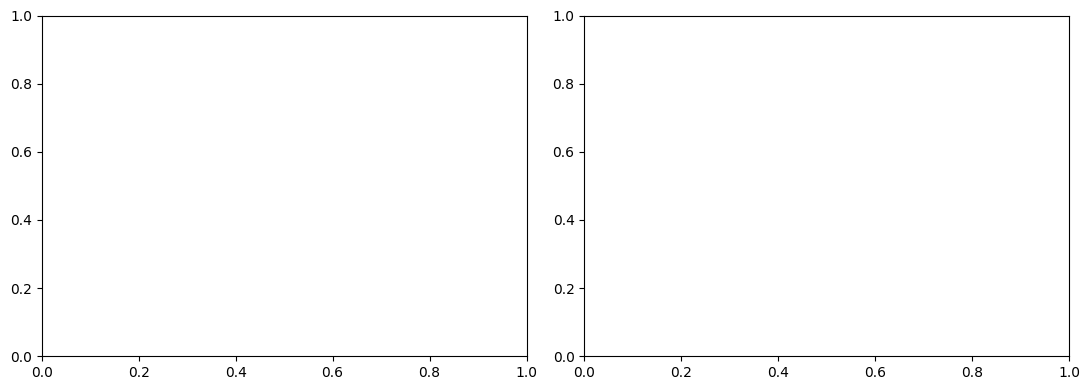

In [13]:
# B3 — Titanic's champion + before/after boxes (tonight's homework)
titanic = pd.read_csv(
    "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
).rename(columns=str.lower)
titanic = titanic[["survived", "pclass", "sex", "age", "fare", "embarked"]].dropna()
X_t = titanic[["pclass", "age", "fare"]].copy()
X_t["is_female"] = (titanic["sex"] == "female").astype(int)
y_t = titanic["survived"]

# TODO: like A5, compute each feature's best-question gain
# TODO: put the champion feature name in B3_champion_feature (one of: "is_female", "pclass", "fare", "age")
# TODO: put the champion's gain in B3_champion_gain (number)
B3_champion_feature = ""
B3_champion_gain = 0.0
print(f"champion: {B3_champion_feature} with gain {B3_champion_gain:.3f}")

# now draw the before/after box (like session 1's charts — complete it yourself)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
# TODO (visual part): in axes[0] the full box: survived/not-survived bars with counts 288 and 424
# TODO (visual part): in axes[1] the two boxes after the champion question: men and women with survivor counts
plt.tight_layout(); plt.show()


---

# PART C — جلسهٔ حل مسئله
*(اول تمرین‌های خانه را زنده حل می‌کنیم — بعد این‌ها را)*

## C1 — بازیِ آستانهٔ ثابت

ماشین می‌گوید `وزن ≥ 14`. ولی `وزن ≥ 20` هم همین‌قدر خوب است؟
برای هر عدد بین ۱ تا ۳۰، بهرهٔ سؤالِ `وزن ≥ عدد` را حساب کن و نمودارش را ببین.


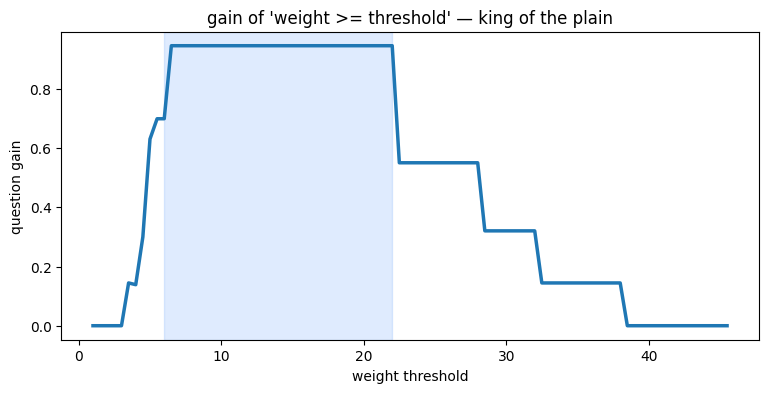

In [14]:
# C1 — the gain-vs-threshold chart
animals = pd.DataFrame({
    "weight": [4.5, 3.0, 6.0, 5.0,   22, 32, 28, 38,   4, 3.5, 4.5],
    "ear_length": [5, 7, 4, 6,        9, 12, 11, 13,    11, 9.5, 10],
    "group": ["cat", "cat", "cat", "cat",
              "big dog", "big dog", "big dog", "big dog",
              "small dog", "small dog", "small dog"],
}, index=["persian", "siamese", "garfield", "chartreux",
          "bulldog", "german", "golden", "doberman",
          "poodle", "yorkshire", "papillon"])
X = animals[["weight", "ear_length"]]
y = animals["group"]

def gain_of(feature, th):
    left  = y[animals[feature] <  th]
    right = y[animals[feature] >= th]
    if len(left) == 0 or len(right) == 0:
        return 0.0
    after = (len(left) * surprise(left) + len(right) * surprise(right)) / len(y)
    return surprise(y) - after

ths = np.arange(1, 46, 0.5)
gains = [gain_of("weight", t) for t in ths]
plt.figure(figsize=(9, 4))
plt.plot(ths, gains, lw=2.5)
plt.axvspan(6, 22, color="#2D7FF9", alpha=0.15)
plt.xlabel("weight threshold"); plt.ylabel("question gain")
plt.title("gain of 'weight >= threshold' — king of the plain")
plt.show()

# discussion: why is every number between 6 and 22 (the blue zone) a champion?
# (because all cats and small dogs are lighter and all big dogs are heavier —
#  any threshold between the two groups locks one spot.)


## C2 — قهرمانِ یک‌حیوانی

جعبهٔ جدید: ۱۰ سگ بزرگ + ۱ گربه.
سؤالِ `وزن ≥ 20` فقط ۱ حیوان را جدا می‌کند. بهره‌اش چقدر است؟
سؤال‌های دیگر هم امتحان کن — سؤالی که «بیشترین حیوان را جدا می‌کند» برنده است یا نه؟


In [15]:
# C2 — the 10+1 box: a small question, a big gain
box = pd.DataFrame({
    "weight": [3.0] + [22, 25, 28, 30, 32, 35, 38, 40, 45, 50],
    "group": ["cat"] + ["big dog"] * 10})
y_box = box["group"]
def gain_box(th):
    left  = y_box[box["weight"] <  th]
    right = y_box[box["weight"] >= th]
    if len(left) == 0 or len(right) == 0:
        return 0.0
    after = (len(left) * surprise(left) + len(right) * surprise(right)) / len(y_box)
    return surprise(y_box) - after

print(f"box surprise: {surprise(y_box):.3f}")
for th in (20, 34, 44, 55):
    print(f"  weight >= {th:3} -> gain: {gain_box(th):.3f}")

# discussion: "weight >= 20" separates only one animal but makes the box fully pure —
# its gain beats "weight >= 34" (which separates 5 animals but keeps both sides mixed).
# champion means the most "sorting", not the most "separating".


box surprise: 0.439
  weight >=  20 -> gain: 0.439
  weight >=  34 -> gain: 0.085
  weight >=  44 -> gain: 0.028
  weight >=  55 -> gain: 0.000


## C3 — راند دومِ تایتانیک: قهرمانِ جعبهٔ زن‌ها

سؤالِ اولِ تایتانیک `is_female` بود. حالا داخلِ جعبهٔ زن‌ها (۲۵۹ نفر، ۷۵٪ زنده)
دوباره بازی کنیم: قهرمانِ راند دوم کیست؟ (کلاس؟ سن؟ کرایه؟)

**بحث پایانی:** سؤال‌ها فقط از میانِ ستون‌های جدول انتخاب می‌شوند.
اگر ستونی دربارهٔ «کدام قایق» وجود داشت چه می‌شد؟ این یعنی انتخابِ ویژگی‌ها
کارِ ماست — ماشین فقط بینِ چیزی که داده‌ایم می‌گردد.


In [16]:
# C3 — round two: the women's box
titanic = pd.read_csv(
    "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
).rename(columns=str.lower)
titanic = titanic[["survived", "pclass", "sex", "age", "fare", "embarked"]].dropna()
X_t = titanic[["pclass", "age", "fare"]].copy()
X_t["is_female"] = (titanic["sex"] == "female").astype(int)
y_t = titanic["survived"]

women = X_t[X_t["is_female"] == 1]
y_w = y_t[X_t["is_female"] == 1]
print(f"women's box: {len(y_w)} people, {y_w.mean():.0%} survived, surprise {surprise(y_w):.2f}")

def gain_w(col):
    vals = sorted(women[col].unique())
    root = surprise(y_w)
    best = 0.0
    for i in range(len(vals) - 1):
        th = (vals[i] + vals[i + 1]) / 2
        left  = y_w[women[col] <= th]
        right = y_w[women[col] >  th]
        if len(left) == 0 or len(right) == 0:
            continue
        after = (len(left) * surprise(left) + len(right) * surprise(right)) / len(y_w)
        best = max(best, root - after)
    return best

for c in ("pclass", "age", "fare"):
    print(f"  best question for {c:10} -> gain: {gain_w(c):.3f}")

# discussion: round two of the real Titanic tree is what you saw in session 1's tree picture.


women's box: 259 people, 75% survived, surprise 0.81
  best question for pclass     -> gain: 0.223
  best question for age        -> gain: 0.013
  best question for fare       -> gain: 0.100
